### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)
    os.makedirs(os.path.join(tmpdir, "chirp"))

/flash/ReiterU/tmp/tomo_CETGUYXCMCKT


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from scipy import signal
import h5py
import cv2
from scipy import ndimage as ndi
from roifile import roiread
import scipy.spatial.distance as dist
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
import matplotlib.patches as mpatches
from sklearn.decomposition import SparsePCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import scanpy as sc
from anndata import AnnData
import leidenalg
import igraph as ig

In [4]:
import sys
sys.path.append("../../")
from calfuncs.io import read_sync_ttl
from calfuncs.full_field_step import plot_chirp_eta, compute_qi

sys.path.append("./")
from plot_functions import characterize_neurons, plot_index, plot_cluster_average, plot_clustering

In [5]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

### load data

In [6]:
with pd.HDFStore("/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/leiden/result_combined.hdf5", mode='r') as store:
    R = store["R"]
    E = store["E"]

### sPCA

In [21]:
X = R[R["good"]].filter(regex="^time_").to_numpy()

# smoothing along row
X = ndi.uniform_filter1d(X, size=3, axis=1, mode='nearest')

# normalization
scaler = StandardScaler(with_std=False)
X_norm = scaler.fit_transform(X)

In [22]:
components = []
S = []
reconstructed = []

for i in range(3):
    M = X_norm[:, i * (420):(i + 1) * (420)].copy()
    spca = SparsePCA(n_components=12, random_state=2025, alpha=3.0, tol=1e-5)
    s = spca.fit_transform(M)
    r = np.dot(s, spca.components_)
    components.append(spca.components_)
    S.append(s)
    reconstructed.append(r)

components = np.vstack(components)
S = np.hstack(S)
reconstructed = np.hstack(reconstructed)

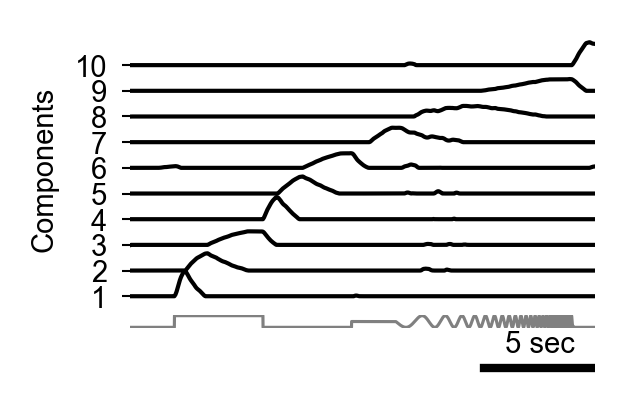

In [43]:
components = spca.components_[0:10]
peak_positions = [np.argmax(row) for row in components]
sort_indices = np.argsort(peak_positions)
components_sorted = components[sort_indices, :]

fig = plt.figure(figsize=(2, 1.5), dpi=300)
gs = fig.add_gridspec(3, 1, height_ratios=[1, 0.05, 0.15], hspace=0.05)

ax = fig.add_subplot(gs[0, 0])
for j in range(components_sorted.shape[0]):
    ax.plot(components_sorted[j]*3 + j + 1, lw=1, color="k")
ax.set_ylabel("Components")
ax.set_xticks([])
ax.set_xlim([0,420])
ax.set_yticks(np.arange(1,11))
# ax.yaxis.set_inverted(True)
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[1, 0])
t = np.arange(21000) * 1e-3
y = np.zeros_like(t)
y[0:2000] = 0
y[2000:6000] = 1
y[6000:10000] = 0
y[10000:12000] = 0.5
y[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
y[20000:21000] = 0
ax.plot(t, y, color="gray", lw=0.75)
ax.set_xlim([t[0], t[-1]])
ax.set_ylim([-0.1, 1.1])
ax.axis("off")

ax = fig.add_subplot(gs[2, 0])
ax.plot([t[-5000], t[-1]], [-0.6, -0.6], color='black', lw=2)
ax.text(t[-2500], 0.5, '5 sec', color='black', ha='center', va='center', rotation=0)
ax.set_xlim([t[0], t[-1]])
ax.set_ylim([-1, 1])
ax.axis("off")

plt.show()

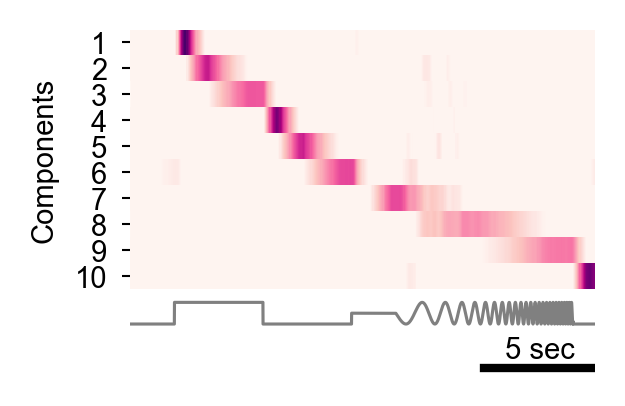

In [35]:
components = spca.components_[0:10]
peak_positions = [np.argmax(row) for row in components]
sort_indices = np.argsort(peak_positions)
components_sorted = components[sort_indices, :]

fig = plt.figure(figsize=(2, 1.5), dpi=300)
gs = fig.add_gridspec(3, 1, height_ratios=[1, 0.1, 0.15], hspace=0.1)

ax = fig.add_subplot(gs[0, 0])
ax.imshow(components_sorted, aspect="auto", interpolation="none", cmap="RdPu")
ax.set_ylabel("Components")
ax.set_xticks([])
ax.set_yticks(np.arange(0,10))
ax.set_yticklabels(np.arange(1,11))
for sp in ["top", "right", "bottom", "left"]:
    ax.spines[sp].set_visible(False)

ax = fig.add_subplot(gs[1, 0])
t = np.arange(21000) * 1e-3
y = np.zeros_like(t)
y[0:2000] = 0
y[2000:6000] = 1
y[6000:10000] = 0
y[10000:12000] = 0.5
y[12000:20000] = 0.5 + 0.5 * signal.chirp(np.linspace(0, 8, 8000), f0=0.5, f1=10, t1=8, method='logarithmic', phi=90)
y[20000:21000] = 0
ax.plot(t, y, color="gray", lw=0.75)
ax.set_xlim([t[0], t[-1]])
ax.set_ylim([-0.1, 1.1])
ax.axis("off")

ax = fig.add_subplot(gs[2, 0])
ax.plot([t[-5000], t[-1]], [-0.6, -0.6], color='black', lw=2)
ax.text(t[-2500], 0.3, '5 sec', color='black', ha='center', va='center', rotation=0)
ax.set_xlim([t[0], t[-1]])
ax.set_ylim([-1, 1])
ax.axis("off")

plt.show()

In [ ]:
for j in range(100):
    i = 0
    # plt.plot(X_norm[j, i * (420):(i + 1) * (420)])
    # plt.plot(reconstructed[j, i * (420):(i + 1) * (420)])
    plt.plot(X_norm[j])
    plt.plot(reconstructed[j])
    plt.show()

### Optimize the number of components

In [56]:
n_components_range = range(2, 21)
alpha_range = [0.5, 1.0, 2, 3]
reconstruction_errors = []

for a in alpha_range:
    for n in n_components_range:
        error = 0
        for i in range(3):
            M = X_norm[:, i * (420):(i + 1) * (420)].copy()
            spca = SparsePCA(n_components=n, random_state=2025, alpha=a, tol=1e-4)
            s = spca.fit_transform(M)
            r = np.dot(s, spca.components_)
            error += np.linalg.norm(M - r, ord='fro')
            # D = X_norm[:, i * (420):(i + 1) * (420)].copy()
            # spca = SparsePCA(n_components=n, random_state=2025, alpha=a, tol=1e-5)
            # D_spca = spca.fit_transform(D)
            # D_reconstructed = np.dot(D_spca, spca.components_)
            # error += np.linalg.norm(D - D_reconstructed, ord='fro')
        reconstruction_errors.append({
            "alpha": a,
            "n": n,
            "error": error
        })

df = pd.DataFrame(data=reconstruction_errors)

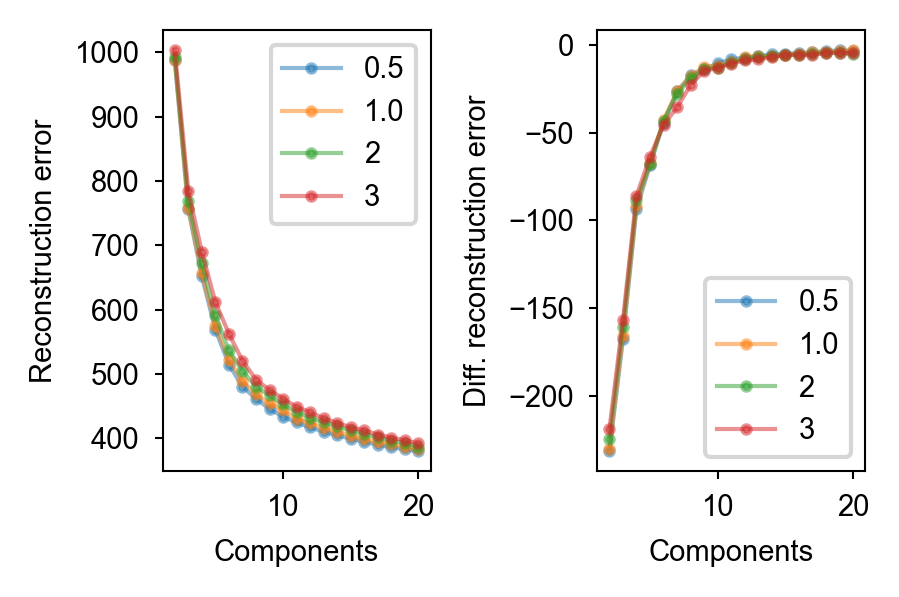

In [57]:
# Plot reconstruction error vs number of components
fig, axs = plt.subplots(1, 2, figsize=(3, 2), dpi=300)

for a in alpha_range:
    y = df[df["alpha"] == a]["error"]
    axs[0].plot(n_components_range, y, lw=1, ms=2, marker='o', alpha=0.5, label=a)
    axs[0].set_xlabel("Components")
    axs[0].set_ylabel("Reconstruction error")
    axs[0].grid()
    
    grad = np.gradient(y)
    axs[1].plot(n_components_range, grad, lw=1, ms=2, marker="o", alpha=0.5, label=a)
    axs[1].grid()
    axs[1].set_xlabel("Components")
    axs[1].set_ylabel("Diff. reconstruction error")
axs[0].legend()
axs[1].legend()
plt.tight_layout()
plt.show()

### Copy data to bucket

In [51]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/sPCA_analysis"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/sPCA_analysis
cp -r /flash/ReiterU/tmp/tomo_CETGUYXCMCKT/* /bucket/ReiterU/OLdev/analysis/20250602_OGL_IGL_clustering_2/sPCA_analysis
